# FXS / 03e — 03d over every downloaded year: trailing stop on EURUSD-01, EURUSD-02, USDJPY-01, USDJPY-02 (2016 → 2026, compounding)

Same rules, costs and account as `03d_trailing_stop.ipynb`, run on all the candle data downloaded: **2016-01 → 2026-11-06**. Results are also split by period, because the periods mean different things:

| Period | What it is for these structures |
|---|---|
| 2016–2020 | **in sample**: the years that found the structures (biased upward) |
| 2021–2025 | the confirmation years (used to pick this set) |
| 2026 | the one-look holdout (already seen in FXS 05/06) |

Iván's rule (2026-11-10), no take-profit:
- **Initial stop −12 pips** from the fill.
- When the trade reaches **+8 pips**, the stop jumps to **+3 pips**.
- It then follows **5 pips behind every new whole pip** of profit, never moving back.

Three versions of every trade, same entries (each structure's frozen start time, every trading day, news days included):

| Version | Exit |
|---|---|
| `BASE` | scheduled end time only (as 03b) |
| `TRAIL+TIME` | trailing stop, or the scheduled end time if no stop is hit first |
| `TRAIL ONLY` | trailing stop only; the trade can run for hours or days. A new entry is skipped while that structure's previous trade is still open |

**Fills (minute data):** entry at the quote at the start time; in each minute the stop is checked against the minute's adverse extreme *before* the favourable extreme can move it (a stop is never raised and hit in the same minute); a minute that opens beyond the stop fills at its open (weekend and news gaps). Costs as 03b: Dukascopy spread × `SPREAD_FACTOR` and `COMMISSION_PER_LOT` per lot round trip. Account: $6,000, each trade sized at entry as L × realised equity (compounding); with `TRAIL ONLY` several trades can be open at once.

**Read with care.** Descriptive: the stop settings were chosen after seeing these years, the structures were picked with 2021–2025 results, and 2026 has been seen (FXS 05/06). EURUSD-01 failed its confirmation.

In [25]:
import json, os, sys, tempfile
import datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

E0 = 6_000.0
LEVERAGES = [1, 2, 3, 5, 10]
COMMISSION_PER_LOT = 3         # USD per lot, round trip
SPREAD_FACTOR = 0.9               # x Dukascopy spread
IDS = ["EURUSD-01", "EURUSD-02", "USDJPY-01", "USDJPY-02"]
FROZEN = {"EURUSD-01": ("UTC", 75, 195, 1), "EURUSD-02": ("NY", 660, 900, -1),
          "USDJPY-01": ("UTC", 55, 115, -1), "USDJPY-02": ("UTC", 25, 55, 1)}
WINDOWS = ((dt.date(2016, 1, 1), dt.date(2020, 12, 31), "discovery"), (dt.date(2021, 1, 1), dt.date(2025, 12, 31), "confirmation"),
           (dt.date(2026, 1, 1), dt.date(2026, 11, 6), "holdout"))
PERIODS = {"2016-2020 (in sample)": (2016, 2020), "2021-2025": (2021, 2025), "2026": (2026, 2026)}

SYNTHETIC = os.environ.get("FXS_SYNTHETIC") == "1"
if SYNTHETIC:
    os.environ["EQUITY_TRADING_DIR"] = os.environ.get("FXS_SYNTH_DIR") or tempfile.mkdtemp(prefix="fxs03e_")
    os.environ.pop("DUKASCOPY_DIR", None)
    LEVERAGES = [1, 5]
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "equity_trading").exists())
sys.path.insert(0, str(ROOT / "src"))
from equity_trading import fx_seasonality as F

cfg = F.FXSConfig()
RULE = F.TrailRule(initial=-12.0, activate=8.0, distance=5.0)
VARIANTS = {"BASE": (F.NO_STOP, True), "TRAIL+TIME": (RULE, True), "TRAIL ONLY": (RULE, False)}
BRANCH = Path.cwd().parent
OUT = Path.cwd() / ("03e_synthetic" if SYNTHETIC else "03e"); OUT.mkdir(exist_ok=True)
pd.set_option("display.width", 220, "display.max_columns", 40)

## 0. Synthetic inputs (smoke run only)

In [26]:
if SYNTHETIC:
    base = Path(os.environ["EQUITY_TRADING_DIR"]) / "Dukascopy"
    for i, p in enumerate(("EURUSD", "USDJPY")):
        F.write_synthetic_candles(base, p, dt.date(2015, 12, 28), dt.date(2026, 11, 6), seed=11 + i, drift_bps=-3.0 if p == "EURUSD" else 0.0,
                                  drift_ny=(4, 8), price=150.0 if p.endswith("JPY") else 1.10)
    cand = pd.DataFrame([{"id": k, "pair": k[:6], "clock": c, "start": s, "end": e, "direction": d} for k, (c, s, e, d) in FROZEN.items()])
else:
    cand = F.load_frozen_candidates(BRANCH).query("id in @IDS").reset_index(drop=True)
for _, r in cand.iterrows():
    assert (r["clock"], int(r["start"]), int(r["end"]), int(r["direction"])) == FROZEN[r["id"]], f"{r['id']} is not the frozen rule"
cand = cand.set_index("id").loc[IDS].reset_index()
display(cand[["id", "pair", "clock", "start", "end", "direction"]].assign(
    rule=[f"{'buy' if d > 0 else 'sell'} {F.slot_label(c, s)} -> {F.slot_label(c, e)}" for c, s, e, d in zip(cand["clock"], cand["start"], cand["end"], cand["direction"])]))

,id,pair,clock,start,end,direction,rule
0,EURUSD-01,EURUSD,UTC,75,195,1,buy UTC 01:15 -> UTC 03:15
1,EURUSD-02,EURUSD,NY,660,900,-1,sell NY 04:00 -> NY 08:00
2,USDJPY-01,USDJPY,UTC,55,115,-1,sell UTC 00:55 -> UTC 01:55
3,USDJPY-02,USDJPY,UTC,25,55,1,buy UTC 00:25 -> UTC 00:55


## 1. Minute data (bid/ask open-high-low-close), 2015-12-31 → 2026-11-06

In [27]:
PAIRS = sorted(set(cand["pair"]))
minutes, days = {}, {}
for p in PAIRS:
    parts = [F.load_minutes_ohlc(p, a, b, st, cfg.min_file_share) for a, b, st in WINDOWS]
    m = pd.concat(parts)
    minutes[p] = F.scale_spread(m[~m.index.duplicated(keep="first")].sort_index(), SPREAD_FACTOR)
    for c in set(cand.loc[cand["pair"] == p, "clock"]):
        days[(p, c)] = np.concatenate([F.build_panel(F.load_minutes(p, a, b, st, min_file_share=cfg.min_file_share), p, c, a, b, cfg.min_coverage).dates
                                       for a, b, st in WINDOWS])
    print(p, len(minutes[p]), "minutes", minutes[p].index[0], "->", minutes[p].index[-1])

EURUSD 5708160 minutes 2015-12-31 00:00:00+00:00 -> 2026-11-06 23:59:00+00:00
USDJPY 5708160 minutes 2015-12-31 00:00:00+00:00 -> 2026-11-06 23:59:00+00:00


## 2. Every trade, three ways

In [28]:
trades = []
for _, r in cand.iterrows():
    for v, (rule, time_exit) in VARIANTS.items():
        t = F.run_structure(minutes[r["pair"]], r["pair"], r["clock"], int(r["start"]), int(r["end"]), int(r["direction"]),
                            days[(r["pair"], r["clock"])], rule, time_exit, COMMISSION_PER_LOT)
        trades.append(t.assign(structure=r["id"], variant=v))
trades = pd.concat(trades, ignore_index=True)
trades["year"] = pd.to_datetime(trades["date"]).dt.year
trades.to_parquet(OUT / "03e_trades.parquet")
print(trades.groupby(["variant", "structure"]).size().unstack())

structure   EURUSD-01  EURUSD-02  USDJPY-01  USDJPY-02
variant                                               
BASE             2816       2816       2816       2816
TRAIL ONLY       2815       2815       2811       2809
TRAIL+TIME       2816       2816       2816       2816


## 3. Per structure: pips, win rate, how trades end, how long they last

In [29]:
def per_structure(t):
    reasons = t["reason"].value_counts(normalize=True)
    return pd.Series({"trades": len(t), "net pips/trade": t["net_pips"].mean(), "win rate": (t["net_pips"] > 0).mean(),
                      "avg win pips": t.loc[t["net_pips"] > 0, "net_pips"].mean(), "avg loss pips": t.loc[t["net_pips"] <= 0, "net_pips"].mean(),
                      "% -12 stop": reasons.get("stop", 0.0), "% trailing": reasons.get("trail", 0.0),
                      "% time / data end": reasons.get("time", 0.0) + reasons.get("end_of_data", 0.0),
                      "median minutes held": t["minutes"].median(), "max hours held": t["minutes"].max() / 60,
                      "worst trade pips": t["net_pips"].min(), "best trade pips": t["net_pips"].max()})
tab = trades.groupby(["structure", "variant"]).apply(per_structure)
display(tab.round(2)); tab.to_csv(OUT / "03e_per_structure.csv")

trades  net pips/trade  win rate  avg win pips  avg loss pips  % -12 stop  % trailing  % time / data end  median minutes held  max hours held  worst trade pips  best trade pips
structure variant                                                                                                                                                                                     
EURUSD-01 BASE        2816.0            0.20      0.50          7.15          -6.83        0.00        0.00               1.00                120.0            2.00           -170.58           171.25
          TRAIL ONLY  2815.0           -0.43      0.59          7.81         -12.30        0.41        0.59               0.00                187.0           82.77            -12.57            53.70
          TRAIL+TIME  2816.0           -0.05      0.53          5.89          -6.78        0.15        0.23               0.62                120.0            2.00            -12.57            42.68
EURUSD-02 BASE        2816.0            1.78      0.53         16.77         -15.41        0.00        0.00               1.00                240.0            4.00           -117.45           148.97
          TRAIL ONLY  2815.0            0.00      0.60          8.05         -12.26        0.39        0.61               0.00                 46.0           78.13            -12.49            62.70
          TRAIL+TIME  2816.0           -0.03      0.60          7.80         -11.55        0.37        0.56               0.07                 46.0            4.00            -12.49            39.71
USDJPY-01 BASE        2816.0            1.04      0.53         11.38         -10.67        0.00        0.00               1.00                 60.0            1.00           -206.50           187.07
          TRAIL ONLY  2811.0            0.64      0.63          8.22         -12.34        0.37        0.63               0.00                 34.0           71.20            -21.45            51.66
          TRAIL+TIME  2816.0            0.65      0.59          7.19          -8.81        0.23        0.41               0.36                 34.0            1.00            -21.45            51.48
USDJPY-02 BASE        2816.0            0.59      0.53          8.44          -8.17        0.00        0.00               1.00                 30.0            0.50           -203.28           100.90
          TRAIL ONLY  2809.0           -0.20      0.60          7.92         -12.32        0.40        0.60               0.00                 34.0           71.97            -12.63            52.67
          TRAIL+TIME  2816.0            0.38      0.57          6.41          -7.46        0.18        0.24               0.58                 30.0            0.50            -12.52            47.78

## 3b. Net pips per trade by period

In [30]:
trades["period"] = None
for name, (a, b) in PERIODS.items():
    trades.loc[trades["year"].between(a, b), "period"] = name
per = trades.pivot_table(index=["structure", "variant"], columns="period", values="net_pips", aggfunc="mean")[list(PERIODS)]
wins = trades.assign(win=trades["net_pips"] > 0).pivot_table(index=["structure", "variant"], columns="period", values="win", aggfunc="mean")[list(PERIODS)]
display(per.round(2)); display((100 * wins).round(1).add_suffix(" win %"))
per.to_csv(OUT / "03e_period_pips.csv")

period                2016-2020 (in sample)  2021-2025  2026
structure variant                                           
EURUSD-01 BASE                         0.84      -0.10 -1.79
          TRAIL ONLY                   0.19      -0.85 -1.61
          TRAIL+TIME                   0.40      -0.28 -1.32
EURUSD-02 BASE                         2.20       1.54  0.71
          TRAIL ONLY                  -0.05      -0.04  0.53
          TRAIL+TIME                  -0.06      -0.11  0.61
USDJPY-01 BASE                         1.40       0.97 -0.69
          TRAIL ONLY                   1.12       0.24  0.15
          TRAIL+TIME                   0.84       0.64 -0.42
USDJPY-02 BASE                         0.52       0.81 -0.21
          TRAIL ONLY                  -0.27      -0.24  0.44
          TRAIL+TIME                   0.46       0.21  0.88

period                2016-2020 (in sample) win %  2021-2025 win %  2026 win %
structure variant                                                             
EURUSD-01 BASE                               52.9             49.1        42.5
          TRAIL ONLY                         62.1             56.9        53.4
          TRAIL+TIME                         55.7             51.8        46.6
EURUSD-02 BASE                               54.0             52.8        53.8
          TRAIL ONLY                         59.7             60.3        64.7
          TRAIL+TIME                         58.9             59.6        62.9
USDJPY-01 BASE                               53.9             53.7        44.8
          TRAIL ONLY                         64.7             62.1        60.6
          TRAIL+TIME                         58.6             60.9        51.6
USDJPY-02 BASE                               51.5             53.9        53.8
          TRAIL ONLY                         59.7             59.7        62.4
          TRAIL+TIME                         54.9             57.8        58.8

## 4. Net pips per trade, year by year

structure EURUSD-01                       EURUSD-02                       USDJPY-01                       USDJPY-02                      
variant        BASE TRAIL ONLY TRAIL+TIME      BASE TRAIL ONLY TRAIL+TIME      BASE TRAIL ONLY TRAIL+TIME      BASE TRAIL ONLY TRAIL+TIME
year                                                                                                                                     
2016           0.64       0.82       0.17      3.37      -0.91      -0.75      0.83       0.78       0.56     -0.13       0.16       0.25
2017           0.93       0.65       0.56      2.77      -0.02      -0.08      1.34       1.70       1.11      0.85      -0.77       0.69
2018           0.84       0.20       0.30      2.46       0.08       0.05      1.22       1.10       0.87      0.99       1.21       1.13
2019           0.41      -0.71       0.39      1.87       0.56       0.59      0.58       0.87       0.86      0.30      -1.20       0.18
2020           1.39      -0.03       0.58      0.55       0.07      -0.08      2.99       1.18       0.80      0.58      -0.75       0.05
2021           0.13      -0.99       0.04      1.84       0.29       0.35      0.46      -0.68       0.26      0.89       0.64       0.75
2022           0.02      -0.40      -0.28      4.15       0.42       0.45      1.81       1.31       1.56      2.24       0.76       1.14
2023           0.12      -1.03      -0.31      1.27       0.13       0.11      0.37       0.46       0.84      0.08      -1.99      -0.63
2024          -0.53      -1.07      -0.33      0.27      -0.18      -0.47      0.86      -0.08       0.35      0.97       0.00       0.62
2025          -0.23      -0.77      -0.50      0.14      -0.85      -0.97      1.34       0.20       0.18     -0.16      -0.60      -0.82
2026          -1.79      -1.61      -1.32      0.71       0.53       0.61     -0.69       0.15      -0.42     -0.21       0.44       0.88

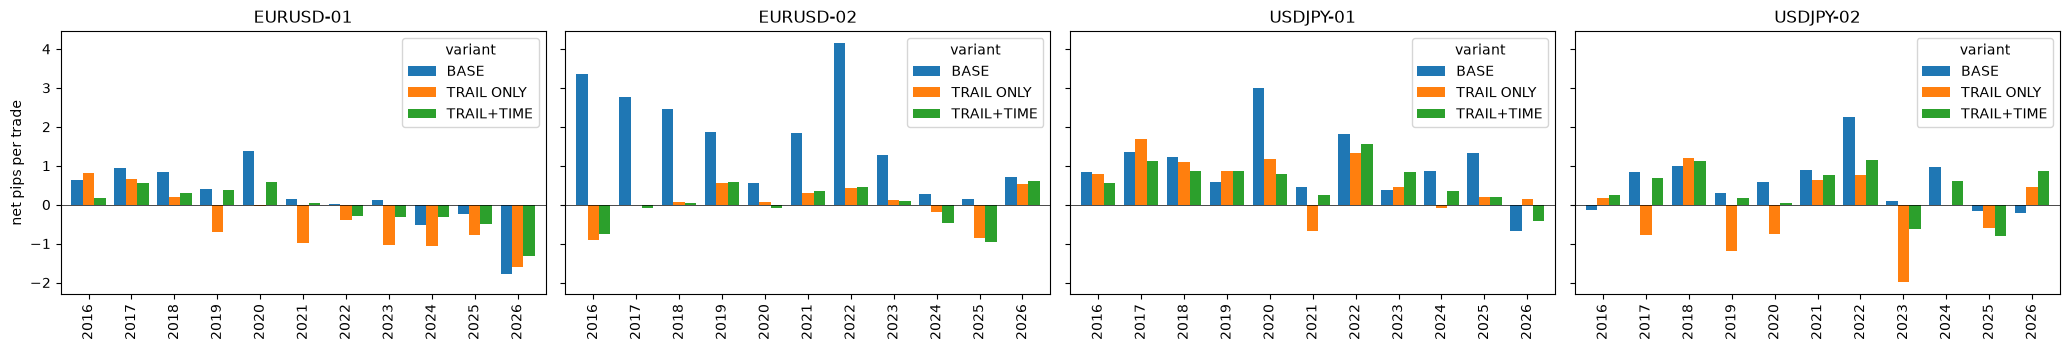

In [31]:
yr = trades.pivot_table(index="year", columns=["structure", "variant"], values="net_pips", aggfunc="mean")
display(yr.round(2)); yr.to_csv(OUT / "03e_yearly_pips.csv")
fig, axes = plt.subplots(1, len(IDS), figsize=(5.2 * len(IDS), 3.6), sharey=True)
for ax, i in zip(axes, IDS):
    yr[i].plot.bar(ax=ax, width=0.8); ax.axhline(0, color="black", lw=0.5); ax.set_title(i); ax.set_xlabel("")
axes[0].set_ylabel("net pips per trade")
plt.tight_layout(); plt.savefig(OUT / "03e_yearly_pips.png", dpi=110); plt.show()

## 5. The compounding account: all four structures together, from $6,000

Equity is realised at each trade's exit (open trades are not marked, so long `TRAIL ONLY` holds understate drawdowns).

,variant,L each,final_equity,cagr,ann_vol,sharpe,max_drawdown,worst_year,best_year,ruined
0,BASE,1,13694.0,7.9%,4.4%,1.712426,-7.3%,-3.1%,19.3%,False
1,BASE,2,32331.0,16.8%,9.0%,1.726873,-14.4%,-6.6%,43.2%,False
2,BASE,3,74573.0,26.2%,13.6%,1.729123,-21.3%,-10.0%,71.1%,False
3,BASE,5,365326.0,46.1%,22.8%,1.728070,-33.9%,-16.6%,140.9%,False
4,BASE,10,13118881.0,103.3%,45.8%,1.728767,-59.2%,-32.8%,432.6%,False
5,TRAIL+TIME,1,7345.0,1.9%,2.4%,0.762191,-7.1%,-4.1%,5.5%,False
6,TRAIL+TIME,2,9038.0,3.9%,5.0%,0.761643,-14.5%,-8.6%,11.7%,False
7,TRAIL+TIME,3,11044.0,5.8%,7.6%,0.760826,-21.4%,-12.9%,18.4%,False
8,TRAIL+TIME,5,16288.0,9.7%,12.7%,0.767127,-33.7%,-20.9%,32.1%,False
9,TRAIL+TIME,10,37490.0,18.4%,25.6%,0.768867,-57.9%,-38.5%,71.5%,False


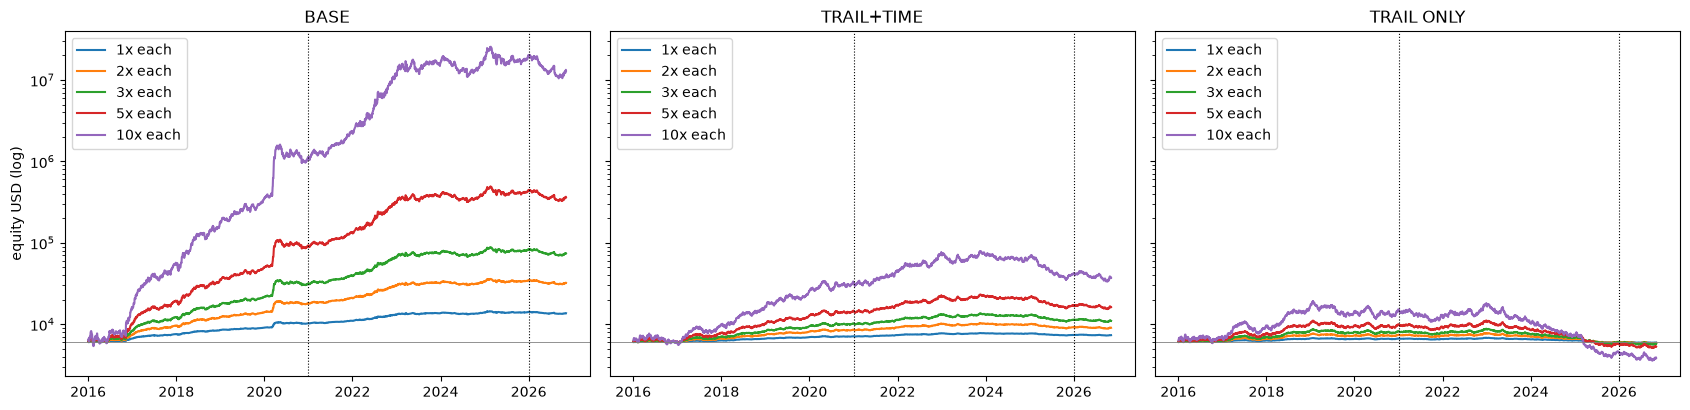

In [32]:
rows, curves = [], {}
for v in VARIANTS:
    tv = trades[trades["variant"] == v]
    for L in LEVERAGES:
        acc = F.simulate_events(tv, L, E0)
        curves[(v, L)] = acc
        rows.append({"variant": v, "L each": L, **F.account_stats(acc, E0)})
res = pd.DataFrame(rows)
show = res.copy()
for c in ("cagr", "ann_vol", "max_drawdown", "worst_year", "best_year"):
    show[c] = (100 * show[c]).round(1).astype(str) + "%"
show["final_equity"] = show["final_equity"].round(0)
display(show); res.to_csv(OUT / "03e_account.csv", index=False)
fig, axes = plt.subplots(1, len(VARIANTS), figsize=(17, 4.2), sharey=True)
for ax, v in zip(axes, VARIANTS):
    for L in LEVERAGES:
        ax.plot(curves[(v, L)]["equity"].clip(lower=1), label=f"{L}x each")
    ax.axhline(E0, color="grey", lw=0.6)
    for b in ("2021-01-01", "2026-01-01"):
        ax.axvline(pd.Timestamp(b), color="black", ls=":", lw=0.8)
    ax.set_yscale("log"); ax.set_title(v); ax.legend()
axes[0].set_ylabel("equity USD (log)")
plt.tight_layout(); plt.savefig(OUT / "03e_equity.png", dpi=110); plt.show()

## 5b. Annual return within each period (separate $6,000 accounts started at each period's first day)

In [33]:
pr = []
for v in VARIANTS:
    for name, (a, b) in PERIODS.items():
        tv = trades[(trades["variant"] == v) & trades["year"].between(a, b)]
        for L in LEVERAGES:
            st = F.account_stats(F.simulate_events(tv, L, E0), E0)
            pr.append({"variant": v, "period": name, "L": L, "cagr %": round(100 * st["cagr"], 1), "max dd %": round(100 * st["max_drawdown"], 1)})
pr = pd.DataFrame(pr)
display(pr.pivot_table(index=["variant", "L"], columns="period", values=["cagr %", "max dd %"])[[("cagr %", p) for p in PERIODS] + [("max dd %", p) for p in PERIODS]])
pr.to_csv(OUT / "03e_period_account.csv", index=False)

cagr %                              max dd %                
period        2016-2020 (in sample) 2021-2025  2026 2016-2020 (in sample) 2021-2025  2026
variant    L                                                                             
BASE       1                   11.4       6.4  -3.5                  -4.4      -4.8  -5.2
           2                   24.8      13.7  -7.8                  -8.8     -10.0 -11.4
           3                   39.5      20.9 -11.5                 -13.3     -15.0 -16.7
           5                   72.9      36.3 -19.3                 -21.6     -24.2 -27.0
           10                 184.9      77.3 -37.5                 -40.3     -44.0 -48.3
TRAIL ONLY 1                    2.2      -1.9  -1.3                  -3.9     -12.2  -2.0
           2                    4.4      -4.0  -2.8                  -8.6     -24.3  -4.4
           3                    6.5      -6.2  -4.5                 -12.8     -35.1  -6.8
           5                   10.8     -10.5  -7.8                 -20.9     -51.7 -11.4
           10                  20.4     -21.3 -16.4                 -39.1     -78.2 -22.4
TRAIL+TIME 1                    3.5       0.7  -1.0                  -3.0      -6.9  -2.6
           2                    7.5       1.3  -1.9                  -5.7     -13.7  -5.4
           3                   11.4       1.9  -2.8                  -8.5     -20.2  -8.1
           5                   19.7       2.9  -5.0                 -14.3     -32.2 -13.5
           10                  41.0       4.4 -10.7                 -27.7     -55.4 -25.9

## 6. Account return year by year (%)

In [34]:
def yearly_returns(acc):
    y = acc["equity"].resample("YE").last()
    r = y.pct_change(); r.iloc[0] = y.iloc[0] / E0 - 1
    r.index = r.index.year
    return r
yrs = pd.DataFrame({(v, f"{L}x"): yearly_returns(curves[(v, L)]) for v in VARIANTS for L in LEVERAGES})
display((100 * yrs).round(1)); yrs.to_csv(OUT / "03e_yearly_returns.csv")

BASE                           TRAIL+TIME                         TRAIL ONLY                        
        1x    2x    3x     5x    10x         1x    2x    3x    5x   10x         1x    2x    3x    5x   10x
2016  11.3  23.5  37.5   67.2  158.9        0.5   1.0   1.3   1.5   0.7        2.0   4.0   5.6   9.2  16.3
2017  13.3  29.9  48.3   92.6  259.5        5.2  10.5  16.1  29.0  63.8        3.6   7.1  10.9  18.5  37.7
2018  12.1  26.7  42.7   80.0  211.5        5.1  10.9  16.8  29.4  65.4        5.7  12.2  18.8  33.1  74.4
2019   7.0  15.1  23.9   42.3   98.2        4.2   9.4  14.5  25.1  55.2       -1.1  -2.6  -3.7  -6.6 -14.3
2020  13.4  29.1  46.3   86.4  223.5        2.8   5.9   9.0  15.5  31.4        0.8   1.7   2.4   3.5   5.5
2021   7.1  15.4  24.1   42.9  100.1        3.1   6.3   9.6  16.4  33.7       -1.5  -3.1  -4.9  -8.6 -17.9
2022  19.3  43.2  71.1  140.9  432.6        5.5  11.7  18.4  32.1  71.5        3.8   8.2  12.5  21.5  44.9
2023   3.9   7.8  11.6   18.8   33.9       -0.3  -0.8  -1.4  -2.6  -6.7       -4.5  -9.6 -14.3 -23.3 -42.4
2024   2.3   4.5   6.6   10.4   16.6       -0.3  -0.9  -1.3  -2.5  -6.2       -3.0  -6.1  -9.3 -15.5 -30.0
2025   1.1   2.6   3.7    5.2    5.3       -4.1  -8.6 -12.9 -20.9 -38.5       -4.4  -8.5 -12.5 -20.5 -38.0
2026  -3.1  -6.6 -10.0  -16.6  -32.8       -0.7  -1.5  -2.4  -4.1  -9.1       -1.3  -2.6  -3.8  -6.6 -13.9

## 7. The same accounts without EURUSD-01 (the 03b set)

EURUSD-01 failed its 2021–2025 confirmation; this shows what including it costs.

In [35]:
rows3 = []
for v in VARIANTS:
    tv = trades[(trades["variant"] == v) & (trades["structure"] != "EURUSD-01")]
    for L in LEVERAGES:
        st = F.account_stats(F.simulate_events(tv, L, E0), E0)
        rows3.append({"variant": v, "L each": L, "final_equity": round(st["final_equity"]), "cagr %": round(100 * st["cagr"], 1),
                      "max drawdown %": round(100 * st["max_drawdown"], 1), "worst year %": round(100 * st["worst_year"], 1)})
display(pd.DataFrame(rows3)); pd.DataFrame(rows3).to_csv(OUT / "03e_account_without_EURUSD01.csv", index=False)

,variant,L each,final_equity,cagr %,max drawdown %,worst year %
0,BASE,1,12988,7.4,-5.1,-0.2
1,BASE,2,29278,15.7,-10.5,0.0
2,BASE,3,64774,24.5,-15.6,-0.2
3,BASE,5,296479,43.3,-25.0,-0.8
4,BASE,10,9369958,97.1,-45.0,-4.4
5,TRAIL+TIME,1,7449,2.0,-5.5,-3.2
6,TRAIL+TIME,2,9297,4.1,-11.3,-6.7
7,TRAIL+TIME,3,11594,6.3,-16.5,-9.9
8,TRAIL+TIME,5,17655,10.5,-26.5,-16.3
9,TRAIL+TIME,10,46102,20.7,-47.3,-30.8


In [36]:
summary = {"study": "FXS03e", "descriptive": True, "synthetic": SYNTHETIC, "structures": IDS, "equity0": E0,
           "rule": {"initial": RULE.initial, "activate": RULE.activate, "distance": RULE.distance},
           "commission_usd_per_lot_rt": COMMISSION_PER_LOT, "spread_factor": SPREAD_FACTOR,
           "per_structure": tab.round(4).reset_index().to_dict(orient="records"), "account": res.to_dict(orient="records"),
           "note": "Stop settings chosen after seeing the data; hindsight structure set; 2026 already seen."}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
print("written", OUT / "summary.json")

written D:\Projects\equity_trading\notebooks\FX_Intraday_Seasonality\Portfolio\03e\summary.json
